## Imports

In [2]:
from pulser import Register
from pulser.devices import DigitalAnalogDevice
from pulser import Sequence
from pulser import Pulse, BlackmanWaveform
from math import pi
import numpy as np
import pulser_simulation
import matplotlib.pyplot as plt

/tmp/ipykernel_3128/2477399102.py:19: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_3128/2477399102.py:19: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_3128/2477399102.py:19: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_3128/2477399102.py:19: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_3128/2477399102.py:19: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_3128/2477399102.py:19: DeprecationWarning: 'QutipB

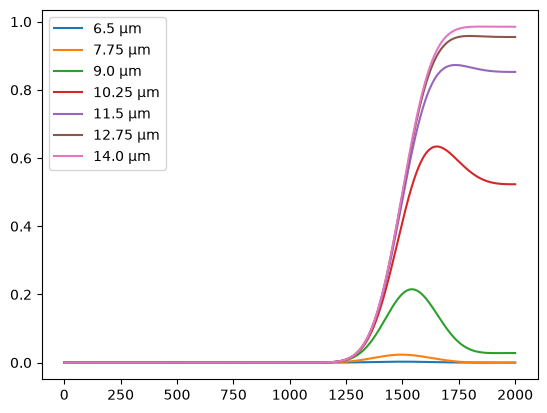

In [55]:
d = np.linspace(6.5, 14, 7)

for i, R in enumerate(d):
  qubits = {"q0": [-R/2, 0], "q1": [R/2, 0]}
  reg = Register(qubits)

  seq = Sequence(reg, DigitalAnalogDevice)
  seq.declare_channel('ch0', 'rydberg_local', initial_target="q0")

  pi_wf = BlackmanWaveform(duration=1000, area=pi)
  pi_pulse = Pulse.ConstantDetuning(amplitude=pi_wf, detuning=0, phase=0)
  seq.add(pi_pulse, "ch0")

  seq.target("q1", "ch0")
  seq.add(pi_pulse, "ch0")

  seq.measure(basis='ground-rydberg')

  sim = pulser_simulation.QutipBackend(seq)
  result = sim.run()
  states = result.states

  r = np.array([1, 0])
  rr = np.kron(r, r)
  occup = np.outer(rr, np.conj(rr))

  plt.plot(np.linspace(0, 2000, 2001), result.expect([occup])[0], label = f"{R} µm")

plt.legend()
plt.show()


On observe que la probabilité d'obtenir le système dans l'état |rr> augmente lorsque la distance R entre les 2 atomes augmente.

Lorsque R est petit, il y a un blocage de Rydberg, après l'excitation du premier atome, le niveau d'énergie de l'état de Rydberg du 2eme atome augmente et le pulse n'est plus à la fréquence résonante donc il est plus compliqué d'exciter le 2eme atome.

Donc plus R augmente, plus il "facile" d'exciter le 2eme atome.

Cela est dû à l'interaction de Van der Waals entre les 2 atomes, qui scale en 1/R^6. Plus R augmente, moins il y a d'interaction entre les 2 atomes et plus il est facile de les exciter indépendamment.